---
title: "Spotify Song's Emotion Analysis"
description: " "
date: 2023-06-21
categories: [Deep Learning, Classification]
image: images/spotify.png
---

<ol class="breadcrumb">
  <li class="breadcrumb-item"><a href="../../home.qmd">Home</a></li>
  <li class="breadcrumb-item"><a href="../ai/index.qmd">Artificial Intelligence Projects</a></li>
  <li class="breadcrumb-item active">Spotify Song's Emotion Analysis</li>
</ol>

## Overview

This notebook investigates the implementation of artificial neural network (ANN) models to classify spotify song's label using the following dataset.

[<i class="bi bi-download"></i> Download Dataset (.csv)](data/spotify.csv){.btn .btn-secondary role="button" download="" target="_blank}

The analysis covers these main steps:

1. Data preprocessing and Exploratory Data Analysis (EDA)
2. Model training
3. Model evaluation

Additionally, hyperparameter tuning via **Keras-Tuner** is systematically applied across some model configurations to determine optimal model parameters and prevent overfitting.

The objective of this notebook is to perform an end-to-end machine learning process, implement a Multi Layer Perceptron (MLP) model, and its hyperparameter tuning.

## Install and Import Packages

In [ ]:
%pip install --upgrade -q keras-tuner matplotlib numpy pandas scikit-learn tensorboard tensorflow

In [1]:
import keras_tuner as kt
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

## Load Dataset

In [2]:
df = pd.read_csv('data/spotify.csv')
df.head()

,duration (ms),danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,spec_rate,labels
0,195000.0,0.611,0.614,-8.815,0.0672,0.0169,0.000794,0.7530,0.520,128.050,3.446154e-07,2
1,194641.0,0.638,0.781,-6.848,0.0285,0.0118,0.009530,0.3490,0.250,122.985,1.464234e-07,1
2,217573.0,0.560,0.810,-8.029,0.0872,0.0071,0.000008,0.2410,0.247,170.044,4.007850e-07,1
3,443478.0,0.525,0.699,-4.571,0.0353,0.0178,0.000088,0.0888,0.199,92.011,7.959809e-08,0
4,225862.0,0.367,0.771,-5.863,0.1060,0.3650,0.000001,0.0965,0.163,115.917,4.693131e-07,1


## Data Preprocessing and EDA

Let's take a look at the overview of the dataset.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 277938 entries, 0 to 277937
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   duration (ms)     277938 non-null  float64
 1   danceability      277938 non-null  float64
 2   energy            277938 non-null  float64
 3   loudness          277938 non-null  float64
 4   speechiness       277938 non-null  float64
 5   acousticness      277938 non-null  float64
 6   instrumentalness  277938 non-null  float64
 7   liveness          277938 non-null  float64
 8   valence           277938 non-null  float64
 9   tempo             277938 non-null  float64
 10  spec_rate         277938 non-null  float64
 11  labels            277938 non-null  int64  
dtypes: float64(11), int64(1)
memory usage: 25.4 MB


Based on the output above, here are some informations about the dataset.
- The dataset has 277938 rows and 12 columns.
- The target variable is 'labels'.
- All features are already in numerical.

Let's also see the distribution of the target variable (labels).

<Axes: xlabel='labels'>

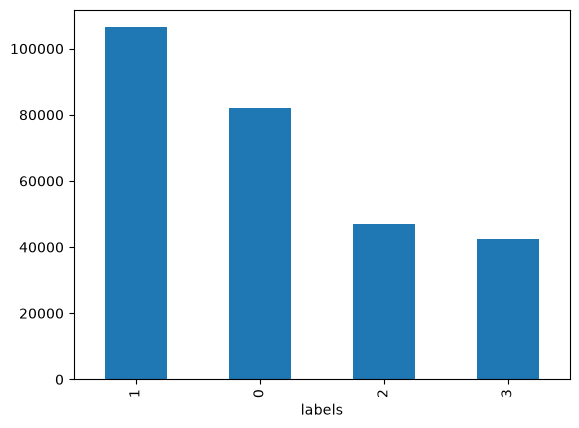

In [9]:
df['labels'].value_counts().plot(kind='bar')

Notice that the labels distribution is imbalance. However, we have massive amount of data (totaling over 270,000 samples). Even the smallest class (Class 3) contains around 40,000 sample which means more than sufficient for modern machine learning algorithms to learn the patterns and features of the class without suffering from a lack of data variety.

### Check and Drop Duplicated Rows (If Exist)

In [4]:
# check and drop duplicated rows (if exist)
total_duplicates = df.duplicated().sum()
print(f'Total duplicated rows: {total_duplicates}')
if total_duplicates:
    df = df.drop_duplicates().reset_index(drop=True)
    print('All duplicated rows has been removed.')
else:
    print('No duplicated rows need to be dropped.')

Total duplicated rows: 1678
All duplicated rows has been removed.


### Check Missing Values

In [5]:
df.isna().sum()

duration (ms)       0
danceability        0
energy              0
loudness            0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
spec_rate           0
labels              0
dtype: int64

### Numerical Features Scaling

Based on the displayed df before, we can see that the numerical features exhibit vastly different scales and measurement ranges. MinMaxScaler is applied to transform all numerical features to transform the data into range $[0,1]$.

Before that, split the the data into train, validation, and test set. Here, we are using 80:10:10 ratio for the train, validation, and test set, respectively. 

We must split our data first, to avoid data leakage

In [6]:
from sklearn.model_selection import train_test_split

target = 'labels'
y = df[target].values

X_df = df.drop(columns=[target])

X_train_df, X_valtest_df, y_train, y_valtest = train_test_split(X_df, y, test_size=0.2, random_state=42)
X_val_df, X_test_df, y_val, y_test = train_test_split(X_valtest_df, y_valtest, test_size=0.5, random_state=42)
print(f'X_train_df shape: {X_train_df.shape}')
print(f'X_val_df shape: {X_val_df.shape}')
print(f'X_test_df shape: {X_test_df.shape}')
print(f'y_train shape: {y_train.shape}')
print(f'y_val shape: {y_val.shape}')
print(f'y_test shape: {y_test.shape}')

X_train_df shape: (221008, 11)
X_val_df shape: (27626, 11)
X_test_df shape: (27626, 11)
y_train shape: (221008,)
y_val shape: (27626,)
y_test shape: (27626,)


In [7]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X_train = X_train_df.values
X_val = X_val_df.values
X_test = X_test_df.values

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

X_train_scaled_df = pd.DataFrame(data=X_train_scaled, columns=X_df.columns)
X_val_scaled_df = pd.DataFrame(data=X_val_scaled, columns=X_df.columns)
X_test_scaled_df = pd.DataFrame(data=X_test_scaled, columns=X_df.columns)

In [8]:
X_train_scaled_df

,duration (ms),danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,spec_rate
0,0.063740,0.496964,0.7730,0.855589,0.033990,0.019980,0.000000,0.1390,0.2960,0.350949,0.002305
1,0.025156,0.533401,0.0896,0.632955,0.034404,0.995984,0.826000,0.1070,0.0509,0.620996,0.005683
2,0.087669,0.741903,0.6240,0.777582,0.051088,0.143574,0.016000,0.3630,0.9210,0.491596,0.002537
3,0.035692,0.142713,0.0193,0.414395,0.044767,0.952811,0.653000,0.1080,0.0642,0.262751,0.005312
4,0.042879,0.738866,0.3440,0.820073,0.065907,0.945783,0.000000,0.7070,0.7260,0.549274,0.006560
...,...,...,...,...,...,...,...,...,...,...,...
221003,0.046574,0.554656,0.9870,0.868472,0.081244,0.000134,0.000303,0.3430,0.3810,0.424925,0.007468
221004,0.033153,0.614372,0.5970,0.788105,0.032021,0.235944,0.005890,0.1450,0.4360,0.497577,0.004076
221005,0.100396,0.566802,0.1440,0.712119,0.044560,0.925703,0.122000,0.1040,0.3280,0.495401,0.001937
221006,0.092121,0.776316,0.7260,0.803610,0.043420,0.000100,0.924000,0.0983,0.0384,0.522603,0.002054


In [9]:
X_val_scaled_df

,duration (ms),danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,spec_rate
0,0.038265,0.820850,0.433,0.793921,0.125389,0.065161,0.000000,0.1040,0.4220,0.551462,0.013921
1,0.101077,0.386640,0.476,0.705547,0.090674,0.646586,0.000001,0.1190,0.6580,0.600142,0.003915
2,0.053011,0.812753,0.701,0.839173,0.031710,0.095984,0.000000,0.1150,0.5020,0.449020,0.002572
3,0.035242,0.400810,0.156,0.675970,0.030674,0.838353,0.000014,0.0791,0.5140,0.338461,0.003684
4,0.051663,0.466599,0.749,0.853506,0.039378,0.236948,0.000000,0.0998,0.5640,0.326683,0.003274
...,...,...,...,...,...,...,...,...,...,...,...
27621,0.055060,0.434211,0.754,0.880367,0.090777,0.019277,0.004810,0.3440,0.5600,0.611745,0.007097
27622,0.044716,0.605263,0.775,0.809843,0.087979,0.558233,0.703000,0.9000,0.1560,0.387921,0.008411
27623,0.077913,0.405870,0.330,0.726113,0.089430,0.914659,0.000000,0.1010,0.3350,0.576855,0.004985
27624,0.045081,0.387652,0.936,0.859708,0.194819,0.000748,0.012300,0.3400,0.0495,0.413796,0.018479


In [10]:
X_test_scaled_df

,duration (ms),danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,spec_rate
0,0.067403,0.574899,0.0533,0.676880,0.042280,0.951807,0.002300,0.1010,0.212,0.469763,0.002715
1,0.059379,0.277328,0.8580,0.841364,0.032435,0.380522,0.208000,0.1720,0.488,0.630508,0.002357
2,0.051501,0.732794,0.6860,0.840145,0.218653,0.021888,0.000000,0.0735,0.451,0.547094,0.018237
3,0.041992,0.695344,0.5630,0.852364,0.039896,0.061948,0.000026,0.4800,0.542,0.312390,0.004052
4,0.065311,0.593117,0.6770,0.796991,0.030466,0.043173,0.093600,0.0884,0.562,0.587886,0.002018
...,...,...,...,...,...,...,...,...,...,...,...
27621,0.041942,0.527328,0.9780,0.904035,0.283938,0.209839,0.272000,0.4240,0.175,0.735547,0.028869
27622,0.056544,0.579960,0.5750,0.807498,0.036373,0.765060,0.569000,0.2990,0.199,0.285494,0.002771
27623,0.156514,0.341093,0.7420,0.861406,0.040933,0.585341,0.000006,0.1960,0.373,0.620955,0.001148
27624,0.052101,0.699393,0.7900,0.845236,0.058135,0.024398,0.000000,0.0453,0.734,0.388031,0.004795


## Train Model with Hyperparameter Tuning

### Hyperparameter Tuning Using Keras-Tuner

In [11]:
# remember always make sure that the X_train/val/test and y_train/val/test are in float32 datatype
# and y_train/val/test is in form of 1 column
X_train = X_train_scaled_df.values.astype(dtype=np.float32)
y_train = y_train.reshape(-1, 1).astype(dtype=np.float32)

X_val = X_val_scaled_df.values.astype(dtype=np.float32)
y_val = y_val.reshape(-1, 1).astype(dtype=np.float32)

print(f'X_train shape: {X_train.shape}')
print(f'y_train shape: {y_train.shape}')

print(f'X_val shape: {X_val.shape}')
print(f'y_val shape: {y_val.shape}')

X_train shape: (221008, 11)
y_train shape: (221008, 1)
X_val shape: (27626, 11)
y_val shape: (27626, 1)


In [15]:
input_size = X_train.shape[1]

def build_model(hp):
    model = tf.keras.Sequential()
    model.add(tf.keras.layers.Input(shape=(input_size,)))

    n_hid_layers = hp.Int('n_hid_layers', min_value=1, max_value=3, step=1)
    for layer in range(n_hid_layers):
        n_neurons = hp.Int(f'n_neurons_{layer}', min_value=8, max_value=128, step=8)
        act = hp.Choice(f'activation_{layer}', 
                        ['linear', 'relu', 'sigmoid', 'tanh'])
        model.add(tf.keras.layers.Dense(n_neurons, activation=act))
    
    model.add(tf.keras.layers.Dense(4, activation='softmax')) # multiclass

    lr = hp.Float('learning_rate', 1e-5, 1e-2)
    opt = tf.keras.optimizers.AdamW(learning_rate=lr)
    model.compile(loss='sparse_categorical_crossentropy', optimizer=opt, metrics=['accuracy']) # multiclass

    return model

In [ ]:
tf.keras.backend.clear_session()

tuner = kt.BayesianOptimization(hypermodel=build_model,
                                objective='val_loss',
                                max_trials=10,
                                directory='tuner_dir_0',
                                project_name='tune_spotify_model',
                                overwrite=False)

tuner.search_space_summary()

Search space summary
Default search space size: 4
n_hid_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
n_neurons_0 (Int)
{'default': None, 'conditions': [], 'min_value': 8, 'max_value': 128, 'step': 8, 'sampling': 'linear'}
activation_0 (Choice)
{'default': 'linear', 'conditions': [], 'values': ['linear', 'relu', 'sigmoid', 'tanh'], 'ordered': False}
learning_rate (Float)
{'default': 1e-05, 'conditions': [], 'min_value': 1e-05, 'max_value': 0.01, 'step': None, 'sampling': 'linear'}


Find the best hyperparameters.

In [17]:
tuner.search(X_train, y_train, validation_data=(X_val, y_val),
             epochs=100, batch_size=256)

Trial 10 Complete [00h 02m 24s]
val_loss: 0.2080817073583603

Best val_loss So Far: 0.18831150233745575
Total elapsed time: 00h 23m 55s


In [18]:
tuner.results_summary(3)

Results summary
Results in tuner_dir_0\tune_spotify_model
Showing 3 best trials
Objective(name="val_loss", direction="min")

Trial 08 summary
Hyperparameters:
n_hid_layers: 3
n_neurons_0: 48
activation_0: tanh
learning_rate: 0.000635494810129079
n_neurons_1: 120
activation_1: tanh
n_neurons_2: 40
activation_2: tanh
Score: 0.18831150233745575

Trial 09 summary
Hyperparameters:
n_hid_layers: 2
n_neurons_0: 96
activation_0: relu
learning_rate: 0.008251039712329468
n_neurons_1: 40
activation_1: linear
n_neurons_2: 48
activation_2: tanh
Score: 0.2080817073583603

Trial 03 summary
Hyperparameters:
n_hid_layers: 1
n_neurons_0: 32
activation_0: relu
learning_rate: 0.004561689776561494
n_neurons_1: 16
activation_1: sigmoid
n_neurons_2: 104
activation_2: relu
Score: 0.2286299765110016


### Retrain Best Model

In [19]:
model = build_model(tuner.get_best_hyperparameters()[0])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 48)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 120)            │         5,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 40)             │         4,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 4)              │           164 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,460 (44.77 KB)

 Trainable params: 11,460 (44.77 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
early_stop = tf.keras.callbacks.EarlyStopping(patience=10, monitor='val_loss',
                                              restore_best_weights=True,
                                              verbose=1)

history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                    epochs=500, batch_size=256, callbacks=[early_stop])

Epoch 1/500
864/864 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8158 - loss: 0.4543 - val_accuracy: 0.8425 - val_loss: 0.3840
Epoch 2/500
864/864 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8489 - loss: 0.3678 - val_accuracy: 0.8511 - val_loss: 0.3580
Epoch 3/500
864/864 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8553 - loss: 0.3492 - val_accuracy: 0.8584 - val_loss: 0.3417
Epoch 4/500
864/864 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8614 - loss: 0.3328 - val_accuracy: 0.8645 - val_loss: 0.3248
Epoch 5/500
864/864 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8661 - loss: 0.3180 - val_accuracy: 0.8644 - val_loss: 0.3175
Epoch 6/500
864/864 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8706 - loss: 0.3054 - val_accuracy: 0.8732 - val_loss: 0.3022
Epoch 7/500
864/864 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8741 - loss: 0.2967 - val_accuracy: 0.8718 - val_loss: 0.2994
Epoch 8/500
864/864 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8766 - loss: 0.2899 - val_accu

## Model Evaluation

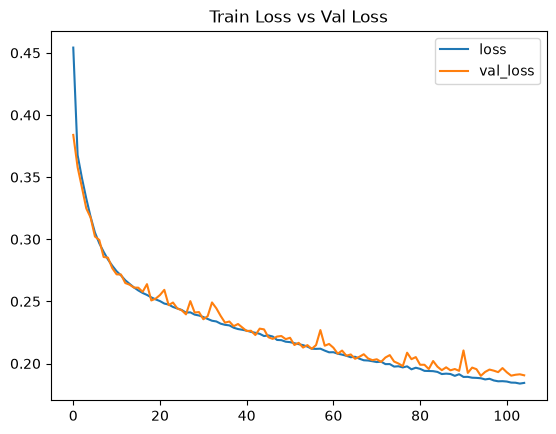

In [21]:
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(len(loss))

plt.plot(epochs, loss)
plt.plot(epochs, val_loss)
plt.legend(['loss', 'val_loss'], loc='upper right')
plt.title('Train Loss vs Val Loss')
plt.show()

- Learning Behavior: Both training loss and validation loss exhibit a smooth, steady decline from around 0.45 down to ~0.18 over 100+ epochs.

- Generalization Capability: The validation loss curve closely tracks the training loss curve without diverging upward. This indicates that the model generalizes remarkably well to unseen data and shows no signs of overfitting.

- Convergence: The minor fluctuations in val_loss are typical in mini-batch gradient descent. Overall, the model reaches a stable convergence around epoch 80–100.

In [22]:
# remember always make sure that the X_train/test and y_train/test are in float32 datatype
# and y_train/test is in form of 1 column
X_test = X_test_scaled_df.values.astype(dtype=np.float32)
y_test = y_test.reshape(-1, 1).astype(dtype=np.float32)

In [23]:
model.evaluate(X_test, y_test)

864/864 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9218 - loss: 0.1833


[0.1833219975233078, 0.9217765927314758]

In [25]:
y_pred_softprob = model(X_test)
y_pred = np.argmax(y_pred_softprob, axis=-1)
print(y_pred)

[0 0 1 ... 0 1 0]


--- Classification Report ---
Classification Report:

              precision    recall  f1-score   support

         0.0       0.93      0.94      0.93      8211
         1.0       0.91      0.92      0.91     10511
         2.0       0.89      0.86      0.87      4632
         3.0       0.97      0.96      0.97      4272

    accuracy                           0.92     27626
   macro avg       0.93      0.92      0.92     27626
weighted avg       0.92      0.92      0.92     27626

--- Confusion Matrix ---


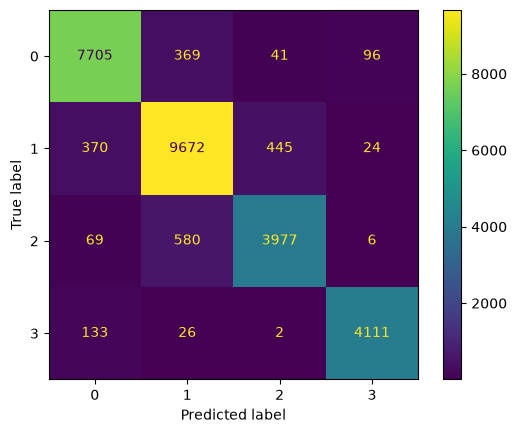

In [26]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print("--- Classification Report ---")
report = classification_report(y_test, y_pred)
print('Classification Report:\n')
print(report)

print("--- Confusion Matrix ---")
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

The model achieves an overall **accuracy of 92%** across a test set of 27,626 samples, with both macro F1-score (0.92) and weighted F1-score (0.92) reflecting high performance across all classes.

The primary source of error occurs between Class 2 and Class 1, where 580 true Class 2 samples were misclassified as Class 1, and 445 true Class 1 samples were misclassified as Class 2. This suggests some feature overlap between these two categories.

**Conclusion:**

The Multi-Layer Perceptron (MLP) model demonstrates robust learning dynamics and high predictive capability across all metrics. Despite the initial class imbalance, the high macro-average F1-score (0.92) confirms that minority classes (such as Class 2 and Class 3) are classified with strong accuracy and reliability.

## Save Model

In [27]:
model.save('model/spotify_mlp.keras')